# `satn_to_time`

Converts a saturation map from an invasion simulation into a time-of-invasion map assuming a constant volumetric flow rate.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import porespy as ps

ps.visualization.set_mpl_style()

Generate a 2D porous medium and run a drainage simulation to obtain a saturation map:

In [2]:
im = ps.generators.blobs([200, 200], porosity=0.6, seed=0)
pc = ps.filters.capillary_transform(im=im, voxel_size=1.0, g=0)
inlets = ps.generators.faces(im.shape, inlet=0)
outlets = ps.generators.faces(im.shape, outlet=0)
inv = ps.simulations.drainage(im=im, pc=pc, inlets=inlets, outlets=outlets)

## `satn` and `im`

Passing `satn` along with the boolean void image `im` converts each invaded voxel's saturation into the elapsed time at which it was invaded. Solid voxels remain `0` and trapped (uninvaded) voxels remain `-1`.

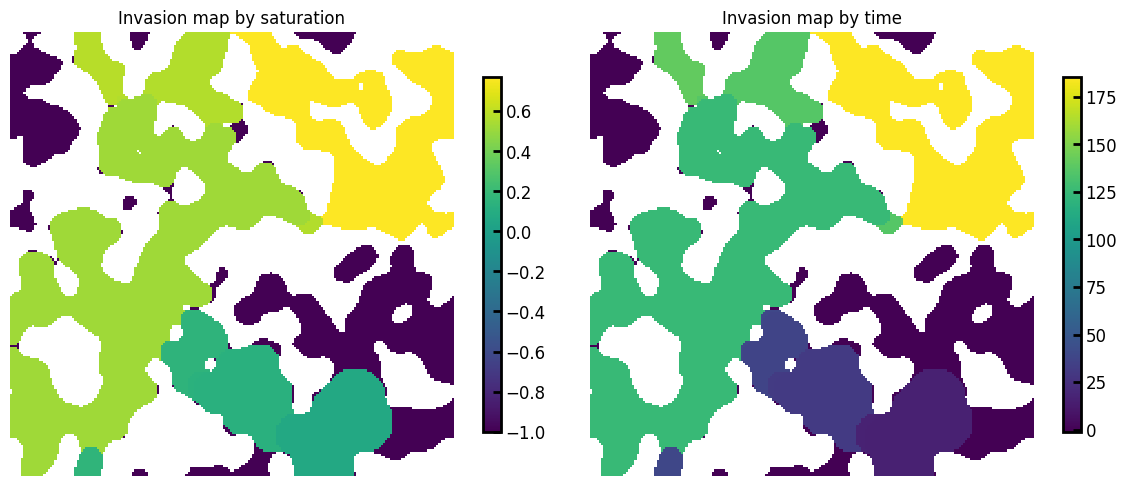

In [3]:
time = ps.filters.satn_to_time(satn=inv.im_snwp, im=im, flow_rate=100.0)

fig, ax = plt.subplots(1, 2, figsize=[12, 5])
im0 = ax[0].imshow(np.where(im, inv.im_snwp, np.nan), origin="lower", interpolation="none")
ax[0].set_title("Invasion map by saturation")
ax[0].axis(False)
fig.colorbar(im0, ax=ax[0], shrink=0.8)

im1 = ax[1].imshow(np.where(im, time, np.nan), origin="lower", interpolation="none")
ax[1].set_title("Invasion map by time")
ax[1].axis(False)
fig.colorbar(im1, ax=ax[1], shrink=0.8);

## `flow_rate` and `voxel_size`

The invasion time scales linearly with the total void volume $V_{\text{void}} = N_{\text{void}} \cdot \text{voxel\_size}^d$ and inversely with `flow_rate`.

In [4]:
t_fast = ps.filters.satn_to_time(satn=inv.im_snwp, im=im, flow_rate=200.0, voxel_size=1.0)
t_fine = ps.filters.satn_to_time(satn=inv.im_snwp, im=im, flow_rate=100.0, voxel_size=0.5)

print(f"Max time (flow_rate=100, voxel_size=1.0): {time.max():.2f}")
print(f"Max time (flow_rate=200, voxel_size=1.0): {t_fast.max():.2f}")
print(f"Max time (flow_rate=100, voxel_size=0.5): {t_fine.max():.2f}")

Max time (flow_rate=100, voxel_size=1.0): 185.66
Max time (flow_rate=200, voxel_size=1.0): 92.83
Max time (flow_rate=100, voxel_size=0.5): 46.41


## `mode`

For `'drainage'` (default), `satn` represents the invading-phase saturation and increases with time. For `'imbibition'`, `satn` represents the defending-phase saturation and decreases with time, so $t = (1 - S) V_{\text{void}} / Q$.

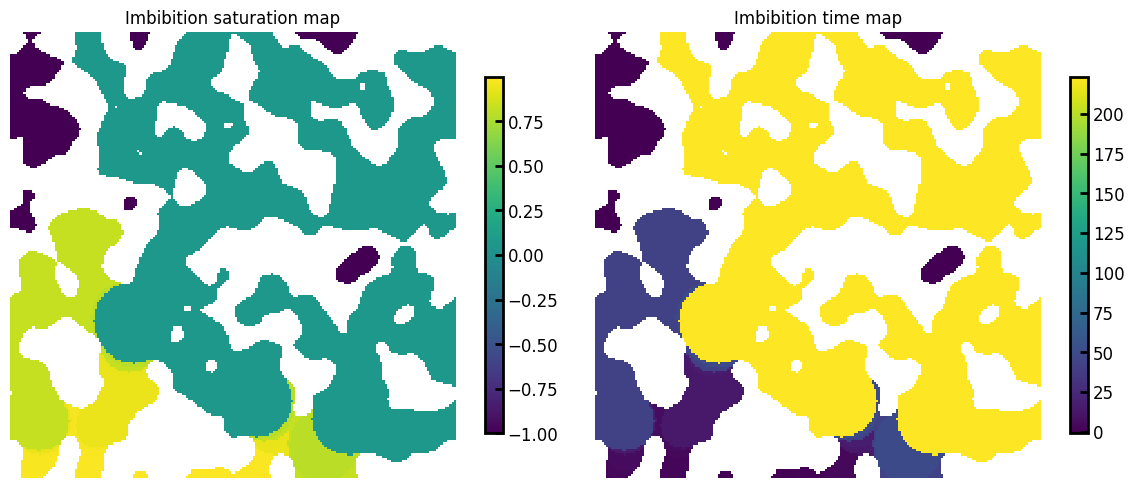

In [5]:
imb = ps.simulations.imbibition(im=im, pc=pc, inlets=inlets)
time_imb = ps.filters.satn_to_time(satn=imb.im_snwp, im=im, flow_rate=100.0, mode="imbibition")

fig, ax = plt.subplots(1, 2, figsize=[12, 5])
im0 = ax[0].imshow(np.where(im, imb.im_snwp, np.nan), origin="lower", interpolation="none")
ax[0].set_title("Imbibition saturation map")
ax[0].axis(False)
fig.colorbar(im0, ax=ax[0], shrink=0.8)

im1 = ax[1].imshow(np.where(im, time_imb, np.nan), origin="lower", interpolation="none")
ax[1].set_title("Imbibition time map")
ax[1].axis(False)
fig.colorbar(im1, ax=ax[1], shrink=0.8);